## Multiple Linear Regression Practise

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Naya complete dataset load karein:
df = pd.read_csv("House_Price_India.csv")
df.head()


,id,Date,number of bedrooms,number of bathrooms,living area,lot area,number of floors,waterfront present,number of views,condition of the house,...,Built Year,Renovation Year,Postal Code,Lattitude,Longitude,living_area_renov,lot_area_renov,Number of schools nearby,Distance from the airport,Price
0,6762810635,42491,4,2.50,2920,4000,1.5,0,0,5,...,1909,0,122004,52.8878,-114.470,2470,4000,2,51,1400000
1,6762810998,42491,5,2.75,2910,9480,1.5,0,0,3,...,1939,0,122004,52.8852,-114.468,2940,6600,1,53,1200000
2,6762812605,42491,4,2.50,3310,42998,2.0,0,0,3,...,2001,0,122005,52.9532,-114.321,3350,42847,3,76,838000
3,6762812919,42491,3,2.00,2710,4500,1.5,0,0,4,...,1929,0,122006,52.9047,-114.485,2060,4500,1,51,805000
4,6762813105,42491,3,2.50,2600,4750,1.0,0,0,4,...,1951,0,122007,52.9133,-114.590,2380,4750,1,67,790000


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14619 entries, 0 to 14618
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     14619 non-null  int64  
 1   Date                                   14619 non-null  int64  
 2   number of bedrooms                     14619 non-null  int64  
 3   number of bathrooms                    14619 non-null  float64
 4   living area                            14619 non-null  int64  
 5   lot area                               14619 non-null  int64  
 6   number of floors                       14619 non-null  float64
 7   waterfront present                     14619 non-null  int64  
 8   number of views                        14619 non-null  int64  
 9   condition of the house                 14619 non-null  int64  
 10  grade of the house                     14619 non-null  int64  
 11  Area of the h

In [3]:
## i am cleaning two columns 

X = df.drop(columns=['id', 'Date', 'Price'])

y = df['Price']

y.head()

0    1400000
1    1200000
2     838000
3     805000
4     790000
Name: Price, dtype: int64

In [4]:
## checking if there are some null or missing values 

df.isnull().sum()

id                                       0
Date                                     0
number of bedrooms                       0
number of bathrooms                      0
living area                              0
lot area                                 0
number of floors                         0
waterfront present                       0
number of views                          0
condition of the house                   0
grade of the house                       0
Area of the house(excluding basement)    0
Area of the basement                     0
Built Year                               0
Renovation Year                          0
Postal Code                              0
Lattitude                                0
Longitude                                0
living_area_renov                        0
lot_area_renov                           0
Number of schools nearby                 0
Distance from the airport                0
Price                                    0
dtype: int6

In [5]:
df.describe()

,id,Date,number of bedrooms,number of bathrooms,living area,lot area,number of floors,waterfront present,number of views,condition of the house,...,Built Year,Renovation Year,Postal Code,Lattitude,Longitude,living_area_renov,lot_area_renov,Number of schools nearby,Distance from the airport,Price
count,1.461900e+04,14619.000000,14619.000000,14619.000000,14619.000000,1.461900e+04,14619.000000,14619.000000,14619.000000,14619.000000,...,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,1.461900e+04
mean,6.762821e+09,42604.546412,3.379233,2.129557,2098.156851,1.509369e+04,1.502326,0.007661,0.232848,3.430399,...,1970.929817,90.930228,122033.064300,52.792843,-114.403996,1996.641836,12754.003078,2.012244,64.951433,5.388063e+05
std,6.237162e+03,67.343747,0.938655,0.769955,928.218740,3.792089e+04,0.540241,0.087196,0.765651,0.664047,...,29.491743,416.230218,19.081451,0.137525,0.141325,691.078387,26059.234785,0.817312,8.936129,3.672294e+05
min,6.762810e+09,42491.000000,1.000000,0.500000,370.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,1900.000000,0.000000,122003.000000,52.385900,-114.709000,460.000000,651.000000,1.000000,50.000000,7.800000e+04
25%,6.762815e+09,42546.000000,3.000000,1.750000,1440.000000,5.010500e+03,1.000000,0.000000,0.000000,3.000000,...,1951.000000,0.000000,122017.000000,52.707600,-114.519000,1490.000000,5097.500000,1.000000,57.000000,3.200000e+05
50%,6.762821e+09,42600.000000,3.000000,2.250000,1930.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,...,1975.000000,0.000000,122032.000000,52.806400,-114.421000,1850.000000,7620.000000,2.000000,65.000000,4.500000e+05
75%,6.762826e+09,42662.000000,4.000000,2.500000,2570.000000,1.080000e+04,2.000000,0.000000,0.000000,4.000000,...,1997.000000,0.000000,122048.000000,52.908900,-114.315000,2380.000000,10125.000000,3.000000,73.000000,6.450000e+05
max,6.762832e+09,42734.000000,33.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,...,2015.000000,2015.000000,122072.000000,53.007600,-113.505000,6110.000000,560617.000000,3.000000,80.000000,7.700000e+06


In [6]:
# sns.pairplot(df)

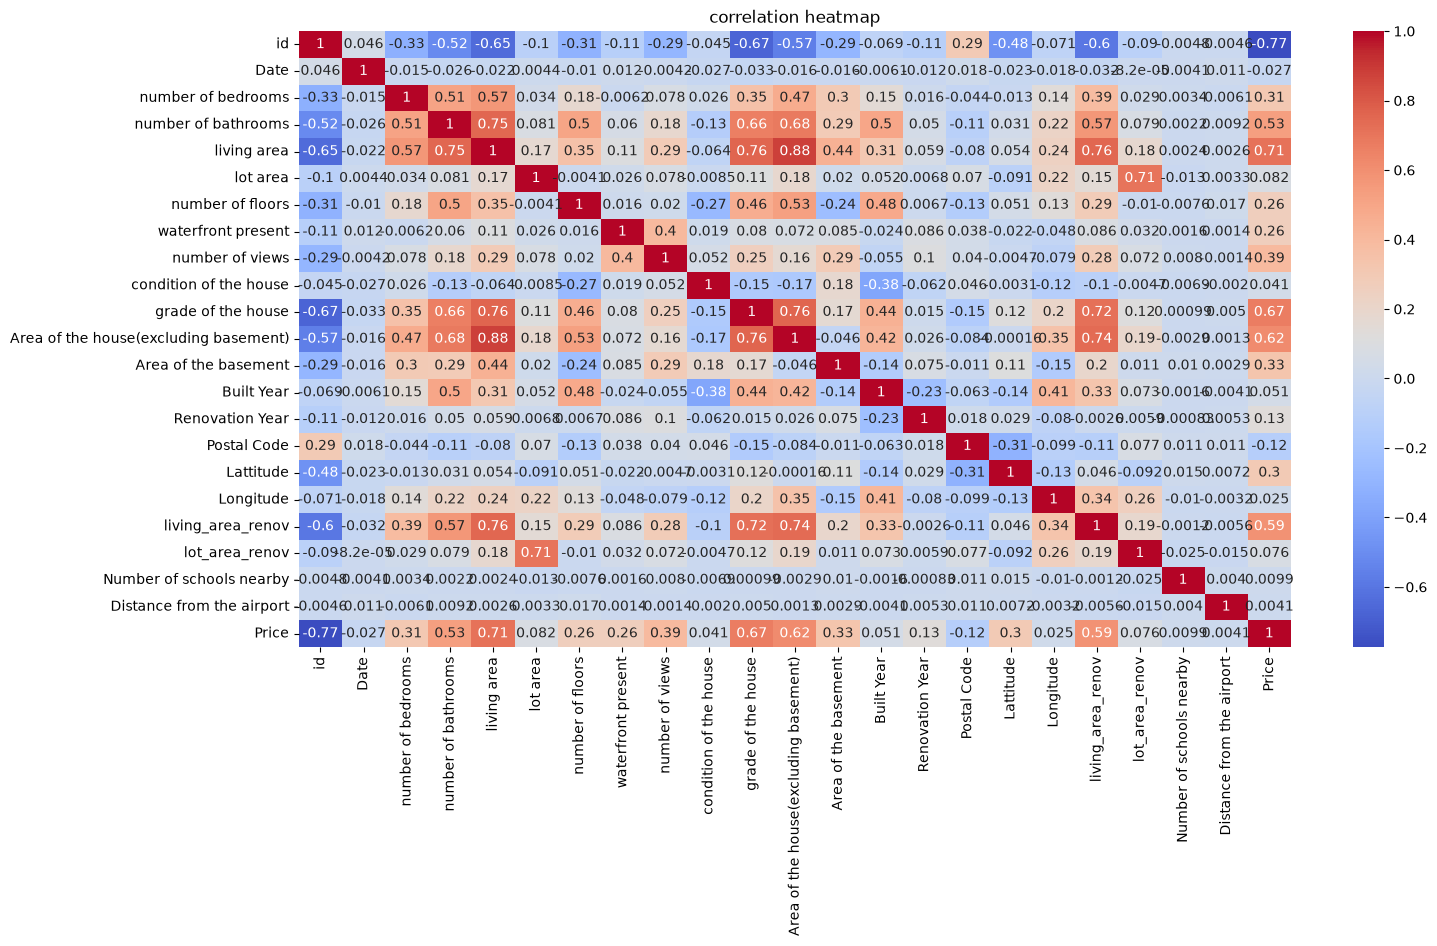

In [7]:
plt.figure(figsize=(16,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("correlation heatmap")
plt.show()

In [8]:
## now Independent and dependent features 

# we have already do in cell 4

In [9]:
# train test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.33, random_state=10)

In [10]:
# checking the shapes 
print(X_train.shape, X_test.shape)


(9794, 20) (4825, 20)


In [11]:
## step 2: Feature Scaling (StandardScaler)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [12]:
## step 3: Model training

from sklearn.linear_model import LinearRegression

regression = LinearRegression()
regression.fit(X_train, y_train) 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[-32948.51, 28598.98, 93860.32,..., -8266.44, 588.19, -2753.17]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.42e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(19)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](20,)","[224.51,142.62,133.74,..., 46.66, 43.03, 0. ]"


In [13]:
print("Coefficients:", regression.coef_)
print("Intercept:", regression.intercept_)

## Yahan aapko 20 alag-alag slopes/weights milenge, kyunki 20 input features milkar Price predict kar rahe hain!

Coefficients: [-32948.50732876  28598.97922394  93860.3177227   -2529.87467088
   2129.65420643  56644.26123849  38977.87054111  22053.60707941
 113162.56609056  90187.3511872   26639.24027666 -74507.09364993
  11551.27332078   7914.75839164  76823.6770616  -14871.94287999
   7756.95132711  -8266.44492323    588.18527699  -2753.16865508]
Intercept: 541966.8534817212


In [14]:
## Step 4: Test data par Predict karein aur Score nikalein

y_pred_test = regression.predict(X_test)

from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred_test)
print("r2 score = ", score)

r2 score =  0.6940431308969139


#### 🔹 2. Jo ab kar rahe hain (`MAE, MSE, RMSE, R²`):
* Yeh hai **Model Evaluation (Exam ke baad ka Report Card)**.
* Model train ho gaya, usne 4,800 naye gharon ki price predict kar di (**`y_pred_test`**).
* Ab hume yeh dekhna hai: **"Model ne andaza kitna sahi lagaya aur kitne rupaye ki galti kari?"**
* **Example:**
  * Ek ghar ki **Asli Price (`y_test`)** thi: **₹50 Lakh**.
  * Model ne **Predict (`y_pred_test`)** kiya: **₹47 Lakh**.
  * Galti (Error) kitni hui: **₹3 Lakh**!

Kya `df.isnull().sum()` se kabhi pata chal sakta tha ki model ₹3 Lakh ki galti karega? **Kabhi nahi!**  
Model kitni galti kar raha hai, yeh tabhi pata chalega jab model se prediction karwaoge aur phir **MAE / MSE** nikaloge.

---

In [15]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

print(mean_squared_error(y_test, y_pred_test))
print(mean_absolute_error(y_test, y_pred_test))
print(np.sqrt(mean_squared_error(y_test, y_pred_test)))

34823244376.68501
125070.05083427187
186609.87213083077


In [16]:
## Step 5: adjusted r score

adj_r2 = 1 - (1 - score) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)



Text(0, 0.5, 'test predicted data')

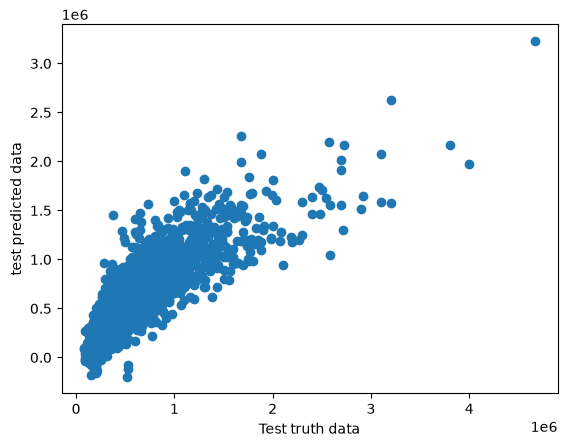

In [17]:
# now whether we have a good model or not so for that we have some assumptions

plt.scatter(y_test, y_pred_test)

plt.xlabel("Test truth data")
plt.ylabel("test predicted data")

In [18]:
## lets see some residuals 

residuals = y_test - y_pred_test

residuals

1128     -94033.065966
12040     47598.804062
7213      13616.307044
5780     228376.471109
14077     19692.163286
             ...      
1466    -115762.853839
5188    -211864.374388
14442    -40728.740656
14073    -75750.655268
1203     -88495.426815
Name: Price, Length: 4825, dtype: float64

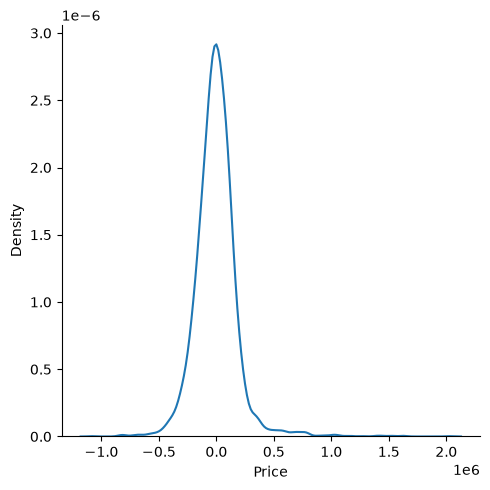

In [19]:
sns.displot(residuals, kind="kde")

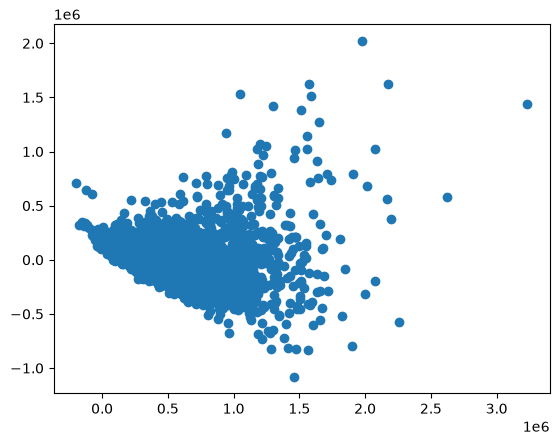

In [20]:
plt.scatter(y_pred_test, residuals)

In [21]:
## python pickling

import pickle

# 1. Model ko save karein ('wb' = write binary)
with open('regmodel.pkl', 'wb') as f:
    pickle.dump(regression, f)

# 2. Scaler ko bhi save karein (kyunki naye data ko scale bhi karna padega)
with open('scaling.pkl', 'wb') as f:
    pickle.dump(scaler, f)


# Model aur scaler ko bina train kiye direct load karein ('rb' = read binary)
pickled_model = pickle.load(open('regmodel.pkl', 'rb'))
pickled_scaler = pickle.load(open('scaling.pkl', 'rb'))

# Naye ghar ka data predict karein:
new_house_data = {
    'number of bedrooms': 4,
    'number of bathrooms': 2.5,
    'living area': 2920,
    'lot area': 4000,
    'number of floors': 1.5,
    'waterfront present': 0,
    'number of views': 0,
    'condition of the house': 5,
    'grade of the house': 8,
    'Area of the house(excluding basement)': 1910,
    'Area of the basement': 1010,
    'Built Year': 1909,
    'Renovation Year': 0,
    'Postal Code': 122004,
    'Lattitude': 52.8878,
    'Longitude': -114.470,
    'living_area_renov': 2470,
    'lot_area_renov': 4000,
    'Number of schools nearby': 2,
    'Distance from the airport': 51
}
# Isko 1-row DataFrame me convert karein:
new_house_df = pd.DataFrame([new_house_data])
# Dekhein kaisa dikh raha hai:
new_house_df

# 1. Scale karein (scaler ko pata chalega kaunsa column kya hai):
new_house_scaled = pickled_scaler.transform(new_house_df)

# 2. Model se Price prediction:
predicted_price = pickled_model.predict(new_house_scaled)[0]

print("=" * 45)
print("🏡 HOUSE PRICE PREDICTION RESULT")
print("=" * 45)
print(f"💰 Raw Predicted Price : ₹ {predicted_price:,.2f}")
print(f"🏷️ Price in Lakhs      : ₹ {predicted_price / 100000:.2f} Lakh")
print("=" * 45)



🏡 HOUSE PRICE PREDICTION RESULT
💰 Raw Predicted Price : ₹ 948,594.77
🏷️ Price in Lakhs      : ₹ 9.49 Lakh


## Lasso linear regression

In [30]:
from sklearn.linear_model import Lasso

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# step1: model define aur train karna (alpha penalty parameter ke saath)

lasso = Lasso(alpha=1.0, max_iter=180000)
lasso.fit(X_train, y_train)

# step2: prediction aur evaluation

y_pred_lasso = lasso.predict(X_test)

print("Lasso --> R2 score", r2_score(y_test, y_pred_lasso))

print("lasso mae: ", mean_absolute_error(y_test, y_pred_lasso))

Lasso --> R2 score 0.694044190900692
lasso mae:  125069.36144270022


In [24]:
y_pred_lasso

array([838025.12184912, 148105.07741399, 235383.35029909, ...,
       495722.21893788, 385735.79367999, 283500.89828755], shape=(4825,))

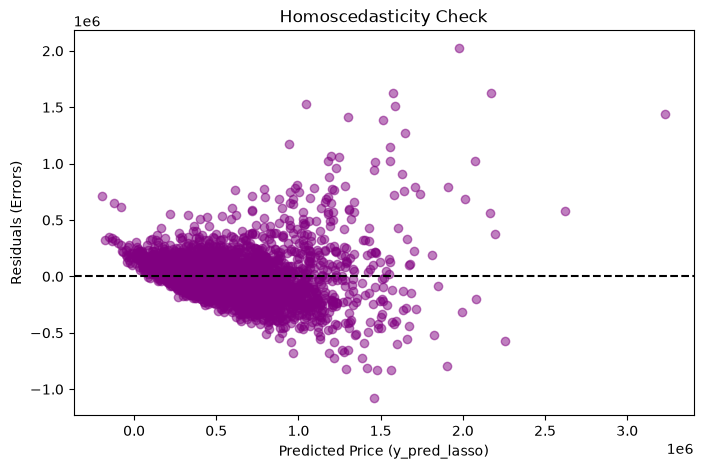

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_lasso, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel("Predicted Price (y_pred_lasso)")
plt.ylabel("Residuals (Errors)")
plt.title("Homoscedasticity Check")
plt.show()


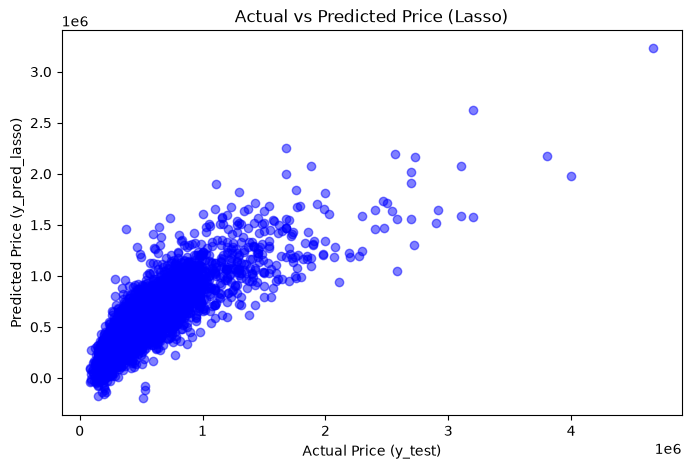

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_lasso, alpha=0.5, color='blue')
plt.xlabel("Actual Price (y_test)")
plt.ylabel("Predicted Price (y_pred_lasso)")
plt.title("Actual vs Predicted Price (Lasso)")
plt.show()


## LassoCV

In [33]:
from sklearn.linear_model import LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# cv=5 ka matlab data ke 5 hisse karke cross-validation karega
lasso_cv = LassoCV(cv=5, max_iter=2000, random_state=10)
lasso_cv.fit(X_train, y_train)

# Dekhiye isne sabse best alpha kya dhoondha:
print("🎯 Best Alpha found by LassoCV:", lasso_cv.alpha_)


🎯 Best Alpha found by LassoCV: 958.9461782369082


In [34]:
## Step2  Test data par prediction karna
y_pred_cv = lasso_cv.predict(X_test)

# Metrics calculate karein
r2_cv = r2_score(y_test, y_pred_cv)
mae_cv = mean_absolute_error(y_test, y_pred_cv)
rmse_cv = np.sqrt(mean_squared_error(y_test, y_pred_cv))

print("📊 LassoCV R2 Score :", r2_cv)
print("📉 LassoCV MAE      :", mae_cv)
print("📉 LassoCV RMSE     :", rmse_cv)


📊 LassoCV R2 Score : 0.6949479384760138
📉 LassoCV MAE      : 124433.08365306813
📉 LassoCV RMSE     : 186333.7367325119


In [35]:
import pandas as pd

# Saare columns aur unke weights ka DataFrame
feature_weights = pd.DataFrame({
    'Feature': X.columns,
    'Weight': lasso_cv.coef_
}).sort_values(by='Weight', ascending=False)

print("--- Saare Features aur unke Coefficients ---")
print(feature_weights)

# Zero features filter karein
eliminated_features = feature_weights[feature_weights['Weight'] == 0]['Feature'].tolist()
print("\n🚫 LassoCV ne in features ko bilkul ZERO (Eliminate) kar diya:")
print(eliminated_features)


--- Saare Features aur unke Coefficients ---
                                  Feature         Weight
2                             living area  150297.284573
8                      grade of the house  113267.361126
14                              Lattitude   75992.171988
5                      waterfront present   56064.842340
6                         number of views   39023.957652
9   Area of the house(excluding basement)   38350.209456
1                     number of bathrooms   26841.003214
7                  condition of the house   21019.203866
12                        Renovation Year   11111.394757
16                      living_area_renov    6626.915319
13                            Postal Code    6410.904334
4                        number of floors    1120.494820
18               Number of schools nearby       0.000000
10                   Area of the basement       0.000000
19              Distance from the airport   -1711.540058
3                                lot area  

## RIDGE REGRESSION

In [36]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# 1. Model define karein (alpha penalty hai)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# 2. Prediction
y_pred_ridge = ridge.predict(X_test)

print("Ridge R2 Score:", r2_score(y_test, y_pred_ridge))
print("Ridge MAE     :", mean_absolute_error(y_test, y_pred_ridge))


Ridge R2 Score: 0.694050512319378
Ridge MAE     : 125065.73545653239


In [37]:
from sklearn.linear_model import RidgeCV

# Alphas ki range test karne ke liye (0.01 se 10000 tak)
alphas = np.logspace(-2, 4, 50)

ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train, y_train)

print("🎯 Best Alpha found by RidgeCV:", ridge_cv.alpha_)

# Predict and Evaluate
y_pred_ridge_cv = ridge_cv.predict(X_test)
print("RidgeCV R2 Score:", r2_score(y_test, y_pred_ridge_cv))
print("RidgeCV MAE     :", mean_absolute_error(y_test, y_pred_ridge_cv))


🎯 Best Alpha found by RidgeCV: 193.06977288832496
RidgeCV R2 Score: 0.695229805643742
RidgeCV MAE     : 124305.49204793


In [38]:
from sklearn.linear_model import ElasticNet

# 50% Lasso aur 50% Ridge ka mix
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=2000)
elastic_net.fit(X_train, y_train)

y_pred_enet = elastic_net.predict(X_test)

print("ElasticNet R2 Score:", r2_score(y_test, y_pred_enet))
print("ElasticNet MAE     :", mean_absolute_error(y_test, y_pred_enet))


ElasticNet R2 Score: 0.6817296935971804
ElasticNet MAE     : 120539.2406792447


In [39]:
from sklearn.linear_model import ElasticNetCV

# Alphas aur l1_ratios dono test karega
enet_cv = ElasticNetCV(
    l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.99],
    cv=5, 
    max_iter=3000, 
    random_state=10
)
enet_cv.fit(X_train, y_train)

print("🎯 Best Alpha    :", enet_cv.alpha_)
print("🎯 Best L1 Ratio :", enet_cv.l1_ratio_)

y_pred_enet_cv = enet_cv.predict(X_test)
print("ElasticNetCV R2 Score:", r2_score(y_test, y_pred_enet_cv))
print("ElasticNetCV MAE     :", mean_absolute_error(y_test, y_pred_enet_cv))


🎯 Best Alpha    : 275.87001126445915
🎯 Best L1 Ratio : 0.99
ElasticNetCV R2 Score: 0.5512598020573902
ElasticNetCV MAE     : 141050.58779388617


## Now we do the pickling the model

### so picking the ML models, preprocessing model standardscaler

'wb' ka matlab hota hai Write Binary (machine readable format me file likhna).



In [ ]:
import pickle

# scaler ko save kare

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f) 
print("scaker.pkl saved successfully !")

# choosen model ko save kare 

with open('House_Price_model.pkl', 'wb') as f:
    pickle.dump(ridge_cv, f)
print("house prediction model saved ")